<h1>Exploratory Data analysis on log traces</h1>

In [ ]:
import os
import json
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.utils import resample
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1.           Load Data                     

In [ ]:
FAIL_CSV = '../../data/raw/failure_trace.csv'
NORM_CSV = '../../data/raw/normal_trace.csv'
FAIL_JSON = '../../data/raw/failure_taskId.json'
NORM_JSON = '../../data/raw/normal_taskId.json'

with open(FAIL_CSV, 'r') as f:
    fail_lines = f.read().splitlines()
df_fail = pd.DataFrame(fail_lines, columns=['raw_trace'])

with open(NORM_CSV, 'r') as f:
    norm_lines = f.read().splitlines()
df_norm = pd.DataFrame(norm_lines, columns=['raw_trace'])

df_fail[['TaskID', 'Trace_Sequence']] = df_fail['raw_trace'].str.split(',', n=1, expand=True)
df_norm[['TaskID', 'Trace_Sequence']] = df_norm['raw_trace'].str.split(',', n=1, expand=True)

# 2. Filter & Label

In [ ]:
with open(FAIL_JSON, 'r') as f:
    fail_ids = [item[0] for item in json.load(f)]
    
with open(NORM_JSON, 'r') as f:
    norm_ids = [item[0] for item in json.load(f)]

df_fail_filtered = df_fail[df_fail['TaskID'].isin(fail_ids)].copy()
df_norm_filtered = df_norm[df_norm['TaskID'].isin(norm_ids)].copy()

df_fail_filtered['Label'] = 1  # 1 = Anomaly (Flaky/Infrastructure)
df_norm_filtered['Label'] = 0  # 0 = Normal

df_master = pd.concat([df_fail_filtered, df_norm_filtered], ignore_index=True)

# 3. Balance Dataset (Downsample Majority)

In [ ]:
df_majority = df_master[df_master['Label'] == 0]
df_minority = df_master[df_master['Label'] == 1]

df_majority_downsampled = resample(df_majority, replace=False, n_samples=len(df_minority), random_state=42)
df_balanced = pd.concat([df_majority_downsampled, df_minority])
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

# 4. Clean & Pad Sequences

In [ ]:
MAX_SEQ_LEN = 100

def clean_and_pad(seq_string):
    tokens = []
    for x in str(seq_string).split(','):
        x = x.strip()
        if x:
            try: tokens.append(int(float(x)))
            except ValueError: pass
    if len(tokens) > MAX_SEQ_LEN: return tokens[:MAX_SEQ_LEN]
    else: return tokens + [0] * (MAX_SEQ_LEN - len(tokens))

df_balanced['Encoded_Sequence'] = df_balanced['Trace_Sequence'].apply(clean_and_pad)

# 5. Tensors & Train/Val Split

In [ ]:
X = torch.tensor(df_balanced['Encoded_Sequence'].tolist(), dtype=torch.long)
y = torch.tensor(df_balanced['Label'].tolist(), dtype=torch.float32)

# SPLIT: 80% Training, 20% Validation
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)

# 6. Model Architecture & Initialization

In [ ]:
class TraceAnomalyLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, num_layers=1, dropout=0.2):
        super(TraceAnomalyLSTM, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=num_layers, batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.fc = nn.Linear(hidden_dim, output_dim)
        self.sigmoid = nn.Sigmoid()
        
    def forward(self, x):
        embedded = self.embedding(x)
        lstm_out, (hidden, cell) = self.lstm(embedded)
        out = self.fc(hidden[-1])
        return self.sigmoid(out).squeeze()

VOCAB_SIZE = int(X.max()) + 1  
EMBEDDING_DIM = 32
HIDDEN_DIM = 64
OUTPUT_DIM = 1

model = TraceAnomalyLSTM(VOCAB_SIZE, EMBEDDING_DIM, HIDDEN_DIM, OUTPUT_DIM)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


# 7. Training & Validation Loop

In [ ]:
EPOCHS = 5
train_losses, val_losses = [], []
train_accs, val_accs = [], []

print("--- STARTING TRAINING ---")
for epoch in range(EPOCHS):
    
    # --- TRAINING PHASE ---
    model.train() 
    epoch_train_loss, correct_train, total_train = 0, 0, 0
    
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        predictions = model(batch_X)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        
        epoch_train_loss += loss.item()
        correct_train += (torch.round(predictions) == batch_y).sum().item()
        total_train += len(batch_y)
        
    avg_train_loss = epoch_train_loss / len(train_loader)
    train_accuracy = (correct_train / total_train) * 100
    
    # --- VALIDATION PHASE ---
    model.eval()
    epoch_val_loss, correct_val, total_val = 0, 0, 0
    
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            predictions = model(batch_X)
            loss = criterion(predictions, batch_y)
            
            epoch_val_loss += loss.item()
            correct_val += (torch.round(predictions) == batch_y).sum().item()
            total_val += len(batch_y)
            
    avg_val_loss = epoch_val_loss / len(val_loader)
    val_accuracy = (correct_val / total_val) * 100
    
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accs.append(train_accuracy)
    val_accs.append(val_accuracy)
    
    print(f"Epoch {epoch+1:02d}/{EPOCHS} | Train Loss: {avg_train_loss:.4f} Acc: {train_accuracy:.2f}% | Val Loss: {avg_val_loss:.4f} Acc: {val_accuracy:.2f}%")

# 8. Visualizations

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# Graph 1: Loss Curve
ax1.plot(train_losses, label='Train Loss', color='blue', marker='o')
ax1.plot(val_losses, label='Validation Loss', color='red', marker='o')
ax1.set_title('Model Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('BCE Loss')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# Graph 2: Accuracy Curve
ax2.plot(train_accs, label='Train Accuracy', color='blue', marker='o')
ax2.plot(val_accs, label='Validation Accuracy', color='green', marker='o')
ax2.set_title('Model Accuracy over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

# Graph 3: Confusion Matrix
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for batch_X, batch_y in val_loader:
        preds = model(batch_X)
        all_preds.extend(torch.round(preds).numpy())
        all_labels.extend(batch_y.numpy())

cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax3, 
            xticklabels=['Normal (0)', 'Anomaly (1)'], 
            yticklabels=['Normal (0)', 'Anomaly (1)'])
ax3.set_title('Validation Confusion Matrix')
ax3.set_xlabel('Predicted Label')
ax3.set_ylabel('True Label')

plt.tight_layout()
plt.show()

# 9. Save Model

--- STARTING TRAINING ---
Epoch 01/5 | Train Loss: 0.6941 Acc: 50.46% | Val Loss: 0.6953 Acc: 49.52%
Epoch 02/5 | Train Loss: 0.6930 Acc: 50.61% | Val Loss: 0.6889 Acc: 60.22%
Epoch 03/5 | Train Loss: 0.3760 Acc: 87.41% | Val Loss: 0.3636 Acc: 88.18%
Epoch 04/5 | Train Loss: 0.3651 Acc: 88.13% | Val Loss: 0.3633 Acc: 88.18%
Epoch 05/5 | Train Loss: 0.3651 Acc: 88.13% | Val Loss: 0.3627 Acc: 88.18%


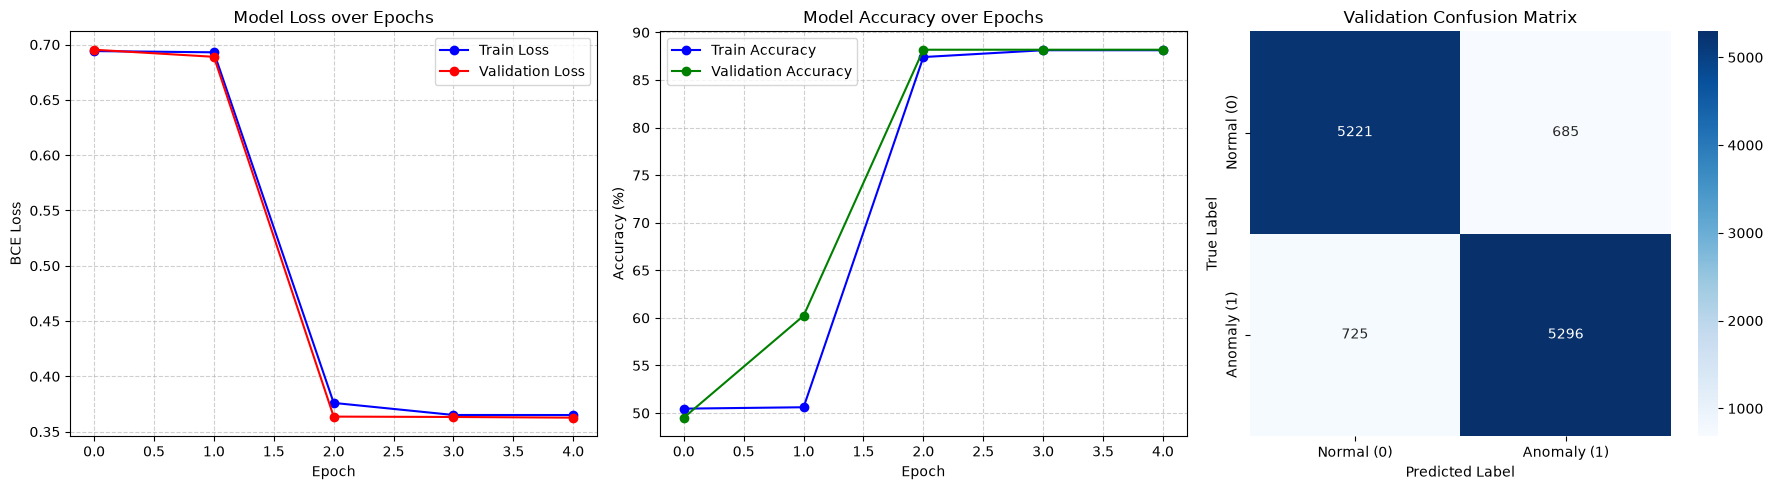

--- EXPORT COMPLETE ---
Model saved to: ../../src/models/saved/trace_anomaly_lstm.pth


In [3]:
os.makedirs('../../src/models/saved', exist_ok=True)
MODEL_PATH = '../../src/models/saved/trace_anomaly_lstm.pth'
torch.save(model.state_dict(), MODEL_PATH)

print("--- EXPORT COMPLETE ---")
print(f"Model saved to: {MODEL_PATH}")